`KNN`에서 `K`값은 새로운 데이터를 예측할 때 참고하는 이웃의 개수를 의미한다.

`K`값처럼 모델이 학습을 통해 스스로 결정하는 것이 아니라, 개발자가 학습 전에 설정하는 값을 **하이퍼파라미터**(Hyperparameter)라고 한다.

```python
model.KNeighborsClassifier(n_neighbors=5)
```

위 코드에서 `n_neighbors=5`가 **하이퍼파라미터**이다.

In [1]:
# 아파트 가격 예측 데이터
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor

# 아파트 면적
X = np.array([
    [10], [15], [20], [24], [27], [30], [35]
])

# 아파트 거래 가격
y = np.array([
    2.0, 3.0, 4.0, 4.8, 5.4, 6.0, 8.0
])

# 예측할 아파트 면적
new_X = np.array([[26]])

for k in [1, 3, 5, 7]:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X, y)

    prediction = model.predict(new_X)

    print(f"K={k}, 예측값={prediction[0]:.2f}")

K=1, 예측값=5.40
K=3, 예측값=5.40
K=5, 예측값=5.64
K=7, 예측값=4.74


`K`값이 작을수록 가까운 개별 데이터의 영향을 많이 받고, `K`값이 클수록 넓은 범위의 데이터를 반영한다.

`K`값이 너무 작으면 가까운 개별 데이터의 패턴이나 데이터의 우연한 특징까지 지나치게 학습하게 되어 새로운 데이터에대한 예측 성능이 떨어지는 **과적합**(Overfitting)이 발생하기 쉽다.

그렇다고 `K`값이 너무 커지면 너무 넓은 범위를 반영하다보니 모델이 데이터에 패턴이나 특징을 충분히 반영하지 못하는 **과소적합**(Underfitting)이 발생하기 쉽다.

때문에 적절한 `K`을 찾는 것이 중요하다.

`KNN`에는 모든 데이터에 공통으로 적용할 수 있는 최적의 `K`이란 존재하지 않는다.

적절한 `K`값을 결정하기 위한 참고 기준으로 아래와 같은 공식을 따를 수 있다.

$K \approx \sqrt{N}$

| 훈련 데이터 개수 | K값 후보 |
| --- | --- |
| 25 | 5 |
| 100 | 10 |
| 400 | 20 |
| 900 | 30 |

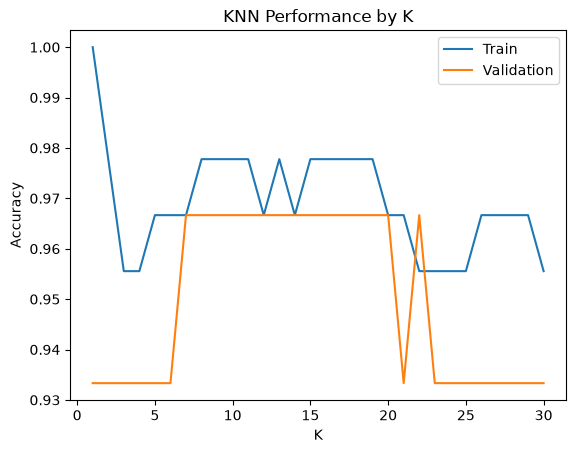

In [2]:
# K값에 따른 모델 성능 비교

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

iris = load_iris()

X = iris.data
y = iris.target

# 훈련용 80%, 테스트용 20%
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 전체 데이터 기준 Train 60%, Validation 20%
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

# 모델 생성 후 K값에 따라 실제 데이터와 예상 데이터를 리스트에 답는다.
k_values = range(1, 31)

train_scores = []
val_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    train_scores.append(model.score(X_train, y_train))
    val_scores.append(model.score(X_val, y_val))

# K값에 따른 성능 시각화
plt.Figure(figsize=(3, 2))

plt.plot(k_values, train_scores, label="Train")
plt.plot(k_values, val_scores, label="Validation")

plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("KNN Performance by K")
plt.legend()
plt.show()

In [3]:
# 최적의 K값 확인하기
# np.argmax() : 배열이나 리스트에서 가장 큰 값을 가진 원소의 인덱스를 반환한다.
best_index = np.argmax(val_scores)

# k_values 는 range(1, 31) 이다.
# 리스트 중 가장 높은 성능을 보인 K값을 가져온다.
best_k = list(k_values)[best_index]

print("Best K:", best_k)
print("Validation Accuracy:", val_scores[best_index])

# 선택된 K값을 가지고 전체 훈련용 데이터를 학습하고, 테스트 데이터에 대한 성능을 확인한다.
model = KNeighborsClassifier(n_neighbors=7)
model.fit(X_train_full, y_train_full)
print(model.score(X_test, y_test))

Best K: 7
Validation Accuracy: 0.9666666666666667
0.9666666666666667
